<a href="https://colab.research.google.com/github/anilkumarsivasankaran-ai/ANILKUMAR-S/blob/main/salary_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
files.upload()

Saving Salary_dataset.csv to Salary_dataset.csv


{'Salary_dataset.csv': b',YearsExperience,Salary\n0,1.2000000000000002,39344.0\n1,1.4000000000000001,46206.0\n2,1.6,37732.0\n3,2.1,43526.0\n4,2.3000000000000003,39892.0\n5,3.0,56643.0\n6,3.1,60151.0\n7,3.3000000000000003,54446.0\n8,3.3000000000000003,64446.0\n9,3.8000000000000003,57190.0\n10,4.0,63219.0\n11,4.1,55795.0\n12,4.1,56958.0\n13,4.199999999999999,57082.0\n14,4.6,61112.0\n15,5.0,67939.0\n16,5.199999999999999,66030.0\n17,5.3999999999999995,83089.0\n18,6.0,81364.0\n19,6.1,93941.0\n20,6.8999999999999995,91739.0\n21,7.199999999999999,98274.0\n22,8.0,101303.0\n23,8.299999999999999,113813.0\n24,8.799999999999999,109432.0\n25,9.1,105583.0\n26,9.6,116970.0\n27,9.7,112636.0\n28,10.4,122392.0\n29,10.6,121873.0\n'}

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [3]:
df = pd.read_csv('Salary_dataset.csv')
df

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0
5,5,3.0,56643.0
6,6,3.1,60151.0
7,7,3.3,54446.0
8,8,3.3,64446.0
9,9,3.8,57190.0


In [4]:
df.shape


(30, 3)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       30 non-null     int64  
 1   YearsExperience  30 non-null     float64
 2   Salary           30 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 852.0 bytes


In [6]:
df.describe()

,Unnamed: 0,YearsExperience,Salary
count,30.000000,30.000000,30.000000
mean,14.500000,5.413333,76004.000000
std,8.803408,2.837888,27414.429785
min,0.000000,1.200000,37732.000000
25%,7.250000,3.300000,56721.750000
50%,14.500000,4.800000,65238.000000
75%,21.750000,7.800000,100545.750000
max,29.000000,10.600000,122392.000000


### Detailed Analysis of Descriptive Statistics

Based on the output of `df.describe()`, here is an analysis of the dataset:

#### 1. Dataset Overview (`count`)
* **Count (30.0)**: There are exactly **30 entries** in this dataset. It is a clean, complete dataset with no missing (null) values in any of the columns.

#### 2. Analysis of `YearsExperience`
* **Mean (5.41 years)**: The average work experience of professionals in this dataset is approximately **5.4 years**.
* **Standard Deviation (2.84 years)**: The standard deviation indicates that most individuals' experience levels deviate from the mean by about $\pm$ 2.8 years, showing a healthy spread of junior, mid-level, and senior professionals.
* **Minimum (1.2 years) & Maximum (10.6 years)**: The dataset ranges from entry-level positions (1.2 years of experience) to highly experienced professionals (10.6 years).
* **Percentiles (IQR)**:
  * **25% (3.3 years)**: 25% of the employees have 3.3 years of experience or less.
  * **50% / Median (4.8 years)**: Half of the employees have less than 4.8 years of experience, and half have more.
  * **75% (7.8 years)**: 75% of the employees have 7.8 years of experience or less.

#### 3. Analysis of `Salary`
* **Mean ($76,004.00)**: The average salary across all 30 individuals is **$76,004.00**.
* **Standard Deviation ($27,414.43)**: There is a wide variation in salaries, with a standard deviation of over **$27,400**. This suggests that salary increases significantly as experience increases.
* **Minimum ($37,732.00) & Maximum ($122,392.00)**: The lowest salary in this dataset is **$37,732.00** (likely corresponding to lower experience levels) and the highest is **$122,392.00**.
* **Percentiles (IQR)**:
  * **25% ($56,721.75)**: 25% of the workforce earns below ~$56.7k.
  * **50% / Median ($65,238.00)**: The median salary is **$65,238.00**.
  * **75% ($100,545.75)**: 75% of the workforce earns below ~$100.5k, showing that the top quartile of experienced individuals commands significantly higher salaries.

#### 4. The `Unnamed: 0` Column
* This column simply represents the original row index (0 to 29) from the CSV. It has a mean of 14.5 and is non-informative for model building. We can safely drop it before training our linear regression model.

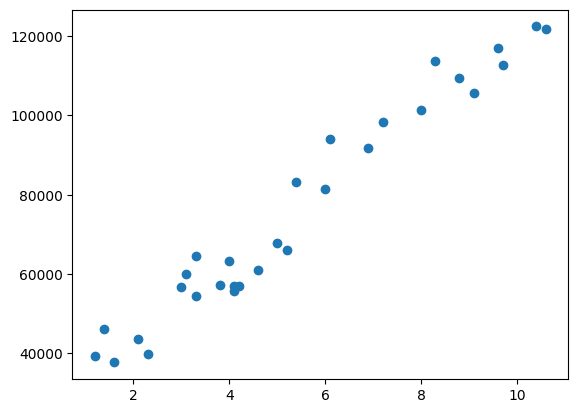

In [7]:
plt.scatter(df['YearsExperience'],df['Salary'])


In [10]:
x = df[['YearsExperience']]
y = df['Salary']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2,random_state=42)
model = LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [11]:
y_pred = model.predict(x_test)


In [13]:
print(df['Salary'].max())
print(df['Salary'].min())
print(df['Salary'].mean())

122392.0
37732.0
76004.0


In [14]:
from sklearn.metrics import mean_squared_error,r2_score

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2_score = r2_score(y_test, y_pred)


In [16]:
rmse
r2_score

0.9024461774180497